# EfficientNetV2 vs EfficientNet-B0 (local run, Windows + NVIDIA GPU)

Local version of the comparison notebook. It reads the datasets from the project's `data/raw` folder,
trains on your **NVIDIA GPU** (mixed precision to save memory and time), and saves weights in the project's models folder.

**Fair-comparison rules (identical for both architectures):** same image subsets, same augmentation and preprocessing
(128 x 128, ImageNet normalisation), same optimiser (AdamW), learning rate, batch size, epochs and seed.
Label convention everywhere: `0 = fake`, `1 = real`, positive class = fake.

**Before running:** make sure the kernel is the `deepfake` environment (Kernel > Change Kernel) and that PyTorch has CUDA (next cell checks it).

## 1. Environment check

In [8]:
import sys, platform
import torch

print("Python  :", sys.version.split()[0], "|", platform.system())
print("PyTorch :", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f"GPU     : {props.name}, {props.total_memory / 1024**3:.1f} GB memory")
else:
    raise RuntimeError(
        "No CUDA GPU visible to PyTorch. Training EfficientNetV2 on the CPU would take hours. "
        "Install the CUDA build of PyTorch in this environment (see the install commands) and restart the kernel.")

Python  : 3.10.22 | Windows
PyTorch : 2.14.1+cu126
CUDA build: 12.6
GPU available: True
GPU     : NVIDIA GeForce RTX 3050 Laptop GPU, 4.0 GB memory


## 2. Setup and configuration

In [10]:
import random, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn as nn
import timm
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms as T
from sklearn.metrics import roc_auc_score, confusion_matrix, accuracy_score, recall_score
from IPython.display import display

warnings.filterwarnings("ignore")
device = "cuda"
torch.backends.cudnn.benchmark = True      # faster convolutions for fixed input size

# Project paths (same config module used by the evaluation script)
try:
    from deepfake_detection.config import DATA_RAW, DATA_PROCESSED, MODELS_DIR
except ImportError:
    DATA_RAW, DATA_PROCESSED, MODELS_DIR = Path("data/raw"), Path("data/processed"), Path("models")
Path(MODELS_DIR).mkdir(parents=True, exist_ok=True)
Path(DATA_PROCESSED).mkdir(parents=True, exist_ok=True)

CIFAKE_ROOT = DATA_RAW / "images ai vs real"
FACES_ROOT  = DATA_RAW / "Facesai vs real" / "real_vs_fake" / "real-vs-fake"
for p in (CIFAKE_ROOT, FACES_ROOT):
    print(("OK       " if p.exists() else "NOT FOUND"), p)

C:\Users\21624\anaconda3\envs\deepfake\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OK        C:\Users\21624\Desktop\deepfake_detection\data\raw\images ai vs real
OK        C:\Users\21624\Desktop\deepfake_detection\data\raw\Facesai vs real\real_vs_fake\real-vs-fake


In [6]:
# ---------------- Configuration (edit here) ----------------
ARCHS = {
    "B0": "efficientnet_b0",
    "V2": "efficientnetv2_rw_s",   # run timm.list_models('efficientnetv2*', pretrained=True) to see alternatives
}
EPOCHS      = 3
LR          = 1e-4
BATCH_SIZE  = 32        # 32 is safe on a 4 GB GPU. Try 64 if you have 6-8 GB and no memory error.
SEED        = 0
USE_AMP     = True      # mixed precision (fp16): less memory, faster on RTX cards
NUM_WORKERS = 0         # 0 is the safest in Jupyter on Windows. Try 2 or 4 to speed up loading; go back to 0 if it errors or hangs.
RUN_FACES   = True      # False = skip the Faces-trained models (saves time)
REUSE_B0    = True      # reuse model_cifake.pth / model_faces.pth (B0 trained on Kaggle) instead of retraining B0

MODELS_DIR = Path(MODELS_DIR)
print(timm.list_models("efficientnetv2*", pretrained=True))

['efficientnetv2_rw_m.agc_in1k', 'efficientnetv2_rw_s.ra2_in1k', 'efficientnetv2_rw_t.ra2_in1k']


### 2.1 Data

Same subsets as the baseline: 20,000 CIFAKE and 12,000 Faces training images, 4,000 test images per dataset.
Faces training uses augmentation (flip, blur, colour jitter); everything else uses plain resize and normalisation.

In [13]:
# ---------------- Configuration ----------------
BATCH_SIZE = 32
NUM_WORKERS = 0

# ---------------- Transformations ----------------
NORM = T.Normalize(
    [0.485, 0.456, 0.406],
    [0.229, 0.224, 0.225]
)

eval_tfm = T.Compose([
    T.Resize((128, 128)),
    T.ToTensor(),
    NORM
])

aug_tfm = T.Compose([
    T.Resize((128, 128)),
    T.RandomHorizontalFlip(),
    T.GaussianBlur(3, sigma=(0.1, 2.0)),
    T.ColorJitter(0.2, 0.2, 0.2),
    T.ToTensor(),
    NORM
])

# ---------------- Dataset Subsampling ----------------
def subset(ds, n, seed):
    random.seed(seed)
    return Subset(ds, random.sample(range(len(ds)), n))


# ---------------- Load Datasets ----------------
cifake_train_full = datasets.ImageFolder(CIFAKE_ROOT / "train", eval_tfm)
cifake_test_full  = datasets.ImageFolder(CIFAKE_ROOT / "test", eval_tfm)

faces_train_full = datasets.ImageFolder(FACES_ROOT / "train", aug_tfm)
faces_test_full  = datasets.ImageFolder(FACES_ROOT / "test", eval_tfm)


# ---------------- Verify Labels ----------------
for name, ds in [
    ("CIFAKE", cifake_train_full),
    ("Faces", faces_train_full)
]:
    mapping = {k.lower(): v for k, v in ds.class_to_idx.items()}
    assert mapping == {"fake": 0, "real": 1}, (
        f"{name}: unexpected labels {ds.class_to_idx}"
    )

print("Label order OK: 0 = fake, 1 = real")


# ---------------- Create Subsets ----------------
cifake_train = subset(cifake_train_full, 20000, 0)
cifake_test  = subset(cifake_test_full, 4000, 0)

faces_train = subset(faces_train_full, 12000, 1)
faces_test  = subset(faces_test_full, 4000, 0)


# ---------------- DataLoaders ----------------
def make_loader(ds, shuffle=False, bs=BATCH_SIZE):
    return DataLoader(
        ds,
        batch_size=bs,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        persistent_workers=NUM_WORKERS > 0
    )


cifake_train_dl = make_loader(cifake_train, shuffle=True)
faces_train_dl = make_loader(faces_train, shuffle=True)

cifake_test_dl = make_loader(cifake_test, bs=64)
faces_test_dl = make_loader(faces_test, bs=64)


# ---------------- Dataset Information ----------------
for name, ds in [
    ("CIFAKE train", cifake_train),
    ("CIFAKE test", cifake_test),
    ("Faces train", faces_train),
    ("Faces test", faces_test)
]:
    print(f"{name:13s}: {len(ds):,} images")

Label order OK: 0 = fake, 1 = real
CIFAKE train : 20,000 images
CIFAKE test  : 4,000 images
Faces train  : 12,000 images
Faces test   : 4,000 images


## 3. Helper functions

- `train_model`: the training loop (with optional mixed precision), parametrised by architecture.
- `evaluate`: AUC, accuracy, recall on the fake class, false positive rate (positive class = fake).
- `get_model`: trains a model, or **reloads saved weights** when the file already exists, so an interrupted run does not lose finished work.

In [18]:

# ============================================================
# CONFIGURATION
# ============================================================

EPOCHS = 3
LR = 1e-4
SEED = 0
USE_AMP = True

# ============================================================
# GRADIENT SCALER
# ============================================================

def make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)


# ============================================================
# MODEL TRAINING
# ============================================================

def train_model(arch, loader, epochs=EPOCHS, lr=LR, seed=SEED):

    if len(loader) == 0:
        raise ValueError("Training DataLoader is empty.")

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    model = timm.create_model(
        arch,
        pretrained=True,
        num_classes=2
    ).to(device)

    n_params = sum(p.numel() for p in model.parameters()) / 1e6

    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    scaler = make_scaler(USE_AMP)

    losses = []
    t0 = time.time()

    for epoch in range(epochs):

        model.train()
        total = 0

        for x, y in loader:

            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            opt.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                loss = loss_fn(model(x), y)

            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()

            total += loss.item()

        epoch_loss = total / len(loader)
        losses.append(epoch_loss)

        elapsed = (time.time() - t0) / 60

        print(
            f"  epoch {epoch+1}/{epochs}: "
            f"loss {epoch_loss:.4f} "
            f"({elapsed:.1f} min elapsed)"
        )

    minutes = (time.time() - t0) / 60

    peak = torch.cuda.max_memory_allocated() / 1024**3

    print(
        f"  -> {arch}: {n_params:.1f}M parameters, "
        f"{minutes:.1f} min, "
        f"peak GPU memory {peak:.1f} GB"
    )

    return model, {
        "params_M": n_params,
        "train_min": minutes,
        "final_loss": losses[-1]
    }


# ============================================================
# LOAD SAVED MODEL WEIGHTS
# ============================================================

def load_weights(arch, path):

    model = timm.create_model(
        arch,
        pretrained=False,
        num_classes=2
    )

    try:
        state = torch.load(
            path,
            map_location=device,
            weights_only=True
        )
    except TypeError:
        state = torch.load(path, map_location=device)

    model.load_state_dict(state)

    n_params = sum(p.numel() for p in model.parameters()) / 1e6

    return model.to(device), {
        "params_M": n_params,
        "train_min": np.nan,
        "final_loss": np.nan
    }


# ============================================================
# GET OR TRAIN MODEL
# ============================================================

def get_model(key, arch, train_name, loader):

    path = MODELS_DIR / f"model_{train_name.lower()}_{key.lower()}.pth"

    legacy = MODELS_DIR / f"model_{train_name.lower()}.pth"

    if path.exists():

        print(f"[{key} / {train_name}] loading saved weights {path.name}")

        return load_weights(arch, path)

    if key == "B0" and REUSE_B0 and legacy.exists():

        print(f"[{key} / {train_name}] reusing existing baseline {legacy.name}")

        return load_weights(arch, legacy)

    print(f"[{key} / {train_name}] training {arch}")

    torch.cuda.reset_peak_memory_stats()

    model, info = train_model(arch, loader)

    torch.save(model.state_dict(), path)

    print(f"  Saved model: {path}")

    return model, info


# ============================================================
# MODEL EVALUATION
# ============================================================

@torch.no_grad()
def evaluate(model, loader):

    model.eval()

    p_fake = []
    y_true = []

    for x, y in loader:

        x = x.to(device, non_blocking=True)

        probs = model(x).float().softmax(1)

        p_fake += probs[:, 0].cpu().tolist()

        y_true += y.tolist()

    y_true = np.array(y_true)
    p_fake = np.array(p_fake)

    # Positive class = fake
    is_fake = (y_true == 0).astype(int)

    pred = (p_fake >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        is_fake,
        pred,
        labels=[0, 1]
    ).ravel()

    return {
        "AUC": roc_auc_score(is_fake, p_fake),
        "Accuracy": accuracy_score(is_fake, pred),
        "Recall (fake)": recall_score(is_fake, pred),
        "FPR": fp / (fp + tn) if (fp + tn) > 0 else np.nan,
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn
    }


# ============================================================
# EXPERIMENT CONFIGURATION
# ============================================================

TEST_LOADERS = {
    "CIFAKE test": cifake_test_dl,
    "Faces test": faces_test_dl
}

rows = []
model_info = {}


# ============================================================
# RUN EXPERIMENTS
# ============================================================

def run_experiment(train_name, train_dl):

    for key, arch in ARCHS.items():

        model, info = get_model(
            key,
            arch,
            train_name,
            train_dl
        )

        model_info[(key, train_name)] = info

        for test_name, dl in TEST_LOADERS.items():

            r = evaluate(model, dl)

            r.update({
                "model": key,
                "trained_on": train_name,
                "tested_on": test_name
            })

            rows.append(r)

            print(
                f"  {key} (trained on {train_name}) "
                f"-> {test_name}: "
                f"AUC={r['AUC']:.3f}  "
                f"Acc={r['Accuracy']:.3f}  "
                f"Recall={r['Recall (fake)']:.3f}  "
                f"FPR={r['FPR']:.3f}"
            )

        del model
        torch.cuda.empty_cache()

print("All training and evaluation functions defined successfully.")


All training and evaluation functions defined successfully.


## 4. Quick speed test (recommended before the full run)

Measures how long a few training batches take for V2, so you can estimate the total time **before** committing to a long run.
If this cell raises `CUDA out of memory`, lower `BATCH_SIZE` in the configuration cell and rerun from there.

In [23]:

# ============================================================
# SPEED TEST CONFIGURATION
# ============================================================

ARCHS = {
    "B0": "efficientnet_b0",
    "V2": "efficientnetv2_rw_s",
}

LR = 1e-4
EPOCHS = 3
USE_AMP = True


# ============================================================
# SPEED TEST FUNCTION
# ============================================================

def speed_test(arch, loader, n_batches=20):

    if len(loader) < 3:
        raise ValueError("Not enough batches for warm-up and speed testing.")

    model = timm.create_model(
        arch,
        pretrained=True,
        num_classes=2
    ).to(device)

    opt = torch.optim.AdamW(model.parameters(), lr=LR)

    loss_fn = nn.CrossEntropyLoss()
    scaler = make_scaler(USE_AMP)

    torch.cuda.reset_peak_memory_stats()

    model.train()

    it = iter(loader)

    # Warm-up: 2 batches
    for _ in range(2):
        x, y = next(it)

        x = x.to(device)
        y = y.to(device)

        opt.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            loss = loss_fn(model(x), y)

        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()

    torch.cuda.synchronize()

    # Actual speed measurement
    t0 = time.time()
    tested_batches = 0

    for x, y in it:

        if tested_batches >= n_batches:
            break

        x = x.to(device)
        y = y.to(device)

        opt.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            loss = loss_fn(model(x), y)

        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()

        tested_batches += 1

    torch.cuda.synchronize()

    elapsed = time.time() - t0

    if tested_batches == 0:
        raise ValueError("No batches were available for testing.")

    per_batch = elapsed / tested_batches

    epoch_min = per_batch * len(loader) / 60

    peak_memory = torch.cuda.max_memory_allocated() / 1024**3

    print(f"\n========== SPEED TEST: {arch} ==========")
    print(f"Measured batches : {tested_batches}")
    print(f"Time per batch   : {per_batch:.2f} seconds")
    print(f"Estimated epoch  : {epoch_min:.1f} minutes")
    print(f"{EPOCHS} epochs        : {epoch_min * EPOCHS:.1f} minutes")
    print(f"Peak GPU memory  : {peak_memory:.2f} GB")

    del model, opt, scaler
    torch.cuda.empty_cache()


# ============================================================
# RUN SPEED TEST
# ============================================================

speed_test(ARCHS["V2"], cifake_train_dl)



========== SPEED TEST: efficientnetv2_rw_s ==========
Measured batches : 20
Time per batch   : 0.36 seconds
Estimated epoch  : 3.8 minutes
3 epochs        : 11.4 minutes
Peak GPU memory  : 1.12 GB


## 5. Models trained on CIFAKE

For each architecture: train on the 20,000 CIFAKE images, then test on **CIFAKE** (same distribution)
and **Faces** (different distribution, the generalisation test).

In [27]:
# ---------------- Configuration ----------------
REUSE_B0 = True

# ---------------- Run CIFAKE Experiment ----------------
run_experiment("CIFAKE", cifake_train_dl)

# ---------------- Display Results ----------------
results_df = pd.DataFrame(rows)

print("\n========== CIFAKE EXPERIMENT RESULTS ==========")

display(
    results_df[
        ["model", "trained_on", "tested_on",
         "AUC", "Accuracy", "Recall (fake)", "FPR"]
    ].round(4)
)

[B0 / CIFAKE] reusing existing baseline model_cifake.pth
  B0 (trained on CIFAKE) -> CIFAKE test: AUC=0.983  Acc=0.936  Recall=0.936  FPR=0.065
  B0 (trained on CIFAKE) -> Faces test: AUC=0.438  Acc=0.483  Recall=0.896  FPR=0.936
[V2 / CIFAKE] training efficientnetv2_rw_s
  epoch 1/3: loss 0.5939 (3.9 min elapsed)
  epoch 2/3: loss 0.1366 (6.1 min elapsed)
  epoch 3/3: loss 0.0725 (8.5 min elapsed)
  -> efficientnetv2_rw_s: 22.2M parameters, 8.5 min, peak GPU memory 1.1 GB
  Saved model: C:\Users\21624\Desktop\deepfake_detection\models\model_cifake_v2.pth
  V2 (trained on CIFAKE) -> CIFAKE test: AUC=0.984  Acc=0.936  Recall=0.948  FPR=0.076
  V2 (trained on CIFAKE) -> Faces test: AUC=0.445  Acc=0.500  Recall=0.973  FPR=0.981

========== CIFAKE EXPERIMENT RESULTS ==========


,model,trained_on,tested_on,AUC,Accuracy,Recall (fake),FPR
0,B0,CIFAKE,CIFAKE test,0.9829,0.9358,0.9365,0.0650
1,B0,CIFAKE,Faces test,0.4376,0.4830,0.8958,0.9360
2,V2,CIFAKE,CIFAKE test,0.9841,0.9365,0.9484,0.0756
3,V2,CIFAKE,Faces test,0.4452,0.4998,0.9732,0.9809


## 6. Models trained on Faces

In [31]:
run_experiment("Faces", faces_train_dl)

[B0 / Faces] reusing existing baseline model_faces.pth
  B0 (trained on Faces) -> CIFAKE test: AUC=0.486  Acc=0.493  Recall=0.068  FPR=0.076
  B0 (trained on Faces) -> Faces test: AUC=0.875  Acc=0.795  Recall=0.786  FPR=0.196
[V2 / Faces] training efficientnetv2_rw_s
  epoch 1/3: loss 0.9523 (3.4 min elapsed)
  epoch 2/3: loss 0.4045 (5.5 min elapsed)
  epoch 3/3: loss 0.2813 (7.8 min elapsed)
  -> efficientnetv2_rw_s: 22.2M parameters, 7.8 min, peak GPU memory 1.1 GB
  Saved model: C:\Users\21624\Desktop\deepfake_detection\models\model_faces_v2.pth
  V2 (trained on Faces) -> CIFAKE test: AUC=0.452  Acc=0.496  Recall=0.007  FPR=0.007
  V2 (trained on Faces) -> Faces test: AUC=0.915  Acc=0.832  Recall=0.843  FPR=0.179


## 7. Comparison

In [33]:
results = pd.DataFrame(rows).set_index(["trained_on", "model", "tested_on"])
display(results[["AUC", "Accuracy", "Recall (fake)", "FPR"]].round(3))

AUC  Accuracy  Recall (fake)    FPR
trained_on model tested_on                                         
CIFAKE     B0    CIFAKE test  0.983     0.936          0.936  0.065
                 Faces test   0.438     0.483          0.896  0.936
           V2    CIFAKE test  0.984     0.936          0.948  0.076
                 Faces test   0.445     0.500          0.973  0.981
Faces      B0    CIFAKE test  0.486     0.493          0.068  0.076
                 Faces test   0.875     0.795          0.786  0.196
           V2    CIFAKE test  0.452     0.496          0.007  0.007
                 Faces test   0.915     0.832          0.843  0.179

In [35]:
view = results["AUC"].unstack("tested_on").round(3)
view["same-domain"] = [view.loc[i, f"{i[0]} test"] for i in view.index]
view["cross-domain"] = [view.loc[i, [c for c in ["CIFAKE test", "Faces test"] if c != f"{i[0]} test"][0]] for i in view.index]
view["generalisation gap"] = (view["same-domain"] - view["cross-domain"]).round(3)
display(view[["same-domain", "cross-domain", "generalisation gap"]])

tested_on         same-domain  cross-domain  generalisation gap
trained_on model                                               
CIFAKE     B0           0.983         0.438               0.545
           V2           0.984         0.445               0.539
Faces      B0           0.875         0.486               0.389
           V2           0.915         0.452               0.463

In [37]:
info = pd.DataFrame(model_info, index=["params_M", "train_min", "final_loss"]).T.round(3)
info.index.names = ["model", "trained_on"]
display(info)   # train_min = NaN means the weights were reloaded, not trained in this run

,,params_M,train_min,final_loss
model,trained_on,,,
B0,CIFAKE,4.010,NaN,NaN
V2,CIFAKE,22.152,8.540,0.072
B0,Faces,4.010,NaN,NaN
V2,Faces,22.152,7.818,0.281


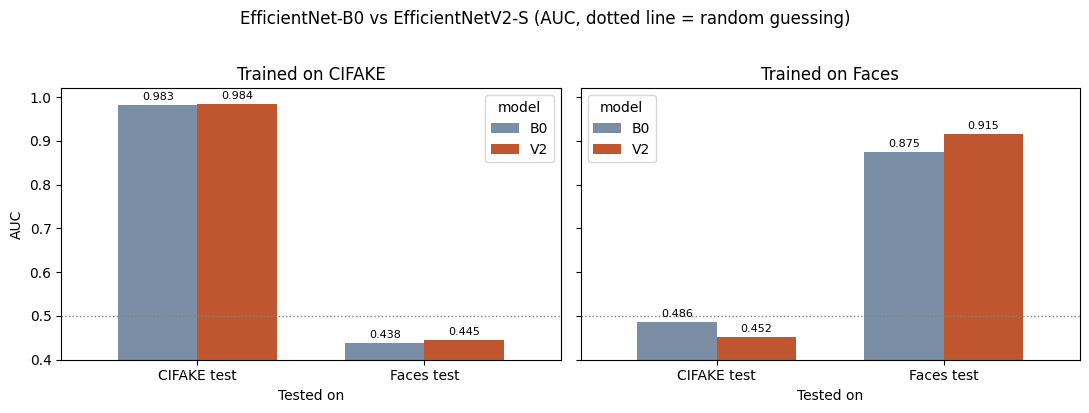

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
colors = {"B0": "#7a8fa6", "V2": "#c0562f"}

for ax, trained_on in zip(axes, ["CIFAKE", "Faces"]):
    if trained_on not in results.index.get_level_values(0):
        ax.set_visible(False); continue
    sub = results.loc[trained_on]["AUC"].unstack("model")
    sub.plot(kind="bar", ax=ax, color=[colors[c] for c in sub.columns], rot=0, width=0.7)
    ax.set_title(f"Trained on {trained_on}")
    ax.set_xlabel("Tested on"); ax.set_ylabel("AUC")
    ax.set_ylim(0.4, 1.02)
    ax.axhline(0.5, color="grey", ls=":", lw=1)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
    ax.legend(title="model")

plt.suptitle("EfficientNet-B0 vs EfficientNetV2-S (AUC, dotted line = random guessing)", y=1.02)
plt.tight_layout()
plt.show()

In [41]:
out = Path(DATA_PROCESSED) / "results_b0_vs_v2.csv"
results.round(4).to_csv(out)
print("Saved:", out)
print("Weights in", MODELS_DIR, ":", sorted(p.name for p in MODELS_DIR.glob("*.pth")))

Saved: C:\Users\21624\Desktop\deepfake_detection\data\processed\results_b0_vs_v2.csv
Weights in C:\Users\21624\Desktop\deepfake_detection\models : ['model_cifake.pth', 'model_cifake_v2.pth', 'model_combined.pth', 'model_faces.pth', 'model_faces_v2.pth']


## 8. Conclusions

*Fill in with your own numbers after running the notebook.*

**Same-domain performance:** B0 AUC `...` / V2 AUC `...`. Is the difference larger than run-to-run noise?

**Cross-dataset generalisation:** generalisation gap B0 `...` vs V2 `...`. Does the larger architecture reduce the gap, or does the training data matter more than the model?

**Cost:** B0 `...` M parameters, `...` min. V2 `...` M parameters, `...` min.

**Caveats to state**
1. Each configuration was trained **once** (single seed). Differences of about 1 AUC point can be noise.
2. Images are 128 x 128 (CIFAKE upscaled from 32 x 32), smaller than the resolution EfficientNetV2 was designed for.
3. Only 3 epochs and data subsets were used because of compute limits.
4. If the B0 baseline was reused from the Kaggle run, it was trained in full precision on a different machine, while V2 used mixed precision here. Retrain B0 locally (`REUSE_B0 = False`) for a strictly identical setup.

**Take-away:** *(one sentence: did V2 beat B0, by how much, and was it worth the extra compute?)*